In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score
)

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

# Mostrar las gráficas dentro del notebook de Jupyter / Colab
get_ipython().run_line_magic('matplotlib', 'inline')

In [8]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

carpetas = [Path('/content/drive/MyDrive/mineriaDatos'), Path('.'), Path('/mnt/data')]
archivos = [
    carpeta / nombre
    for carpeta in carpetas
    for nombre in ['online_shoppers_sin_duplicados.csv', 'online_shoppers_intention.csv']
]
archivo = next((p for p in archivos if p.exists()), None)
if archivo is None:
    raise FileNotFoundError('Coloca online_shoppers_sin_duplicados.csv en la carpeta mineriaDatos de tu Drive.')

df = pd.read_csv(archivo)
if archivo.name == 'online_shoppers_intention.csv':
    df = df.drop_duplicates().reset_index(drop=True)

print('Archivo utilizado:', archivo)
print('Forma del dataset:', df.shape)
print('Distribución de Revenue:')
print(df['Revenue'].value_counts())
display(df.head())

Mounted at /content/drive
Archivo utilizado: /content/drive/MyDrive/mineriaDatos/online_shoppers_sin_duplicados.csv
Forma del dataset: (12205, 20)
Distribución de Revenue:
Revenue
False    10297
True      1908
Name: count, dtype: int64


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,PaginasTotales,VisitoInformativas
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False,1,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False,2,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False,1,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False,2,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False,10,0


###  Definir X e Y

- **X:** información de navegación utilizada para la predicción.
- **Y:** `Revenue` convertido a 0 (no compró) y 1 (sí compró).
- Tratamos `OperatingSystems`, `Browser`, `Region` y `TrafficType` como categorías aunque sean códigos enteros.
- `SpecialDay` permanece entre las variables numéricas.
- Excluimos `PageValues` por precaución ante una posible fuga de información: el análisis de su disponibilidad temporal se realizará aparte.

In [9]:
variables_numericas = [
    'Administrative', 'Administrative_Duration',
    'Informational', 'Informational_Duration',
    'ProductRelated', 'ProductRelated_Duration',
    'BounceRates', 'ExitRates', 'SpecialDay'
]
columnas_onehot = [
    'Month', 'OperatingSystems', 'Browser',
    'Region', 'TrafficType', 'VisitorType'
]

columnas_caracteristicas = variables_numericas + columnas_onehot + ['Weekend']
X = df[columnas_caracteristicas].copy()
Y = df['Revenue'].astype(int)

print('Características originales:', X.shape[1])
print('Clases de Revenue:')
print(Y.value_counts())

Características originales: 16
Clases de Revenue:
Revenue
0    10297
1     1908
Name: count, dtype: int64


### Dividir entrenamiento y prueba — igual que en regresión logística

Se usa 80 % para aprender y 20 % para evaluar. `stratify=Y` conserva aproximadamente la proporción de compradores y no compradores.

In [10]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.20,
    random_state=42,
    stratify=Y
)
print('Entrenamiento:', X_train.shape)
print('Prueba:', X_test.shape)
print('Porcentaje de compras en entrenamiento:', round(Y_train.mean() * 100, 2))
print('Porcentaje de compras en prueba:', round(Y_test.mean() * 100, 2))

Entrenamiento: (9764, 16)
Prueba: (2441, 16)
Porcentaje de compras en entrenamiento: 15.63
Porcentaje de compras en prueba: 15.65


### One-Hot Encoding

Realizamos la misma codificación que en el notebook de regresión logística. De esta manera ambos modelos utilizan **las mismas características**. Ajustamos las columnas de prueba a las existentes en entrenamiento, sin inventar nuevas categorías ni utilizar información de prueba para definir las columnas de entrenamiento.

In [11]:
X_train_aux = X_train.copy()
X_test_aux = X_test.copy()

for variable in columnas_onehot:
    X_train_aux[variable] = X_train_aux[variable].astype(str)
    X_test_aux[variable] = X_test_aux[variable].astype(str)

X_train_aux['Weekend'] = X_train_aux['Weekend'].astype(int)
X_test_aux['Weekend'] = X_test_aux['Weekend'].astype(int)

X_train_cod = pd.get_dummies(X_train_aux, columns=columnas_onehot, dtype=int)
X_test_cod = pd.get_dummies(X_test_aux, columns=columnas_onehot, dtype=int)
X_test_cod = X_test_cod.reindex(columns=X_train_cod.columns, fill_value=0)

print('Columnas codificadas:', X_train_cod.shape[1])
print('Entrenamiento:', X_train_cod.shape)
print('Prueba:', X_test_cod.shape)
print('Datos faltantes:', int(X_train_cod.isna().sum().sum() + X_test_cod.isna().sum().sum()))
assert X_train_cod.columns.equals(X_test_cod.columns)
assert X_train_cod.shape[1] == 72
assert len(X_test_cod) == 2441

Columnas codificadas: 72
Entrenamiento: (9764, 72)
Prueba: (2441, 72)
Datos faltantes: 0


### Entrenar un árbol de decisión estándar



In [12]:
dt = DecisionTreeClassifier(
    criterion='gini',
    min_samples_leaf=10,
    min_impurity_decrease=0.001,
    random_state=42
)
dt.fit(X_train_cod, Y_train)

Y_pred_train = dt.predict(X_train_cod)
Y_pred_test = dt.predict(X_test_cod)

print('Profundidad del árbol:', dt.get_depth())
print('Número de hojas:', dt.get_n_leaves())
display(pd.DataFrame({'Real':Y_test, 'Predicho':Y_pred_test}, index=Y_test.index).head(10))

Profundidad del árbol: 5
Número de hojas: 9


,Real,Predicho
11640,0,0
6936,0,0
7194,0,0
11263,0,0
4728,0,0
9878,0,1
8101,0,0
6642,0,0
10215,0,0
10224,0,0


### Evaluar el árbol estándar con la matriz de confusión


**Filas = resultado real. Columnas = resultado predicho.**
- TN: no compró y el árbol acertó.
- FP: no compró, pero el árbol predijo compra.
- FN: sí compró, pero el árbol predijo que no.
- TP: sí compró y el árbol acertó.

Prestamos especial atención a **Recall de «Sí compró»**, ya que la clase de compra es minoritaria.

=== Árbol de decisión estándar — prueba ===
              precision    recall  f1-score   support

   No compró       0.86      0.97      0.91      2059
   Sí compró       0.45      0.13      0.21       382

    accuracy                           0.84      2441
   macro avg       0.65      0.55      0.56      2441
weighted avg       0.79      0.84      0.80      2441

Matriz de confusión:
[[1997   62]
 [ 331   51]]
TN=1997, FP=62, FN=331, TP=51


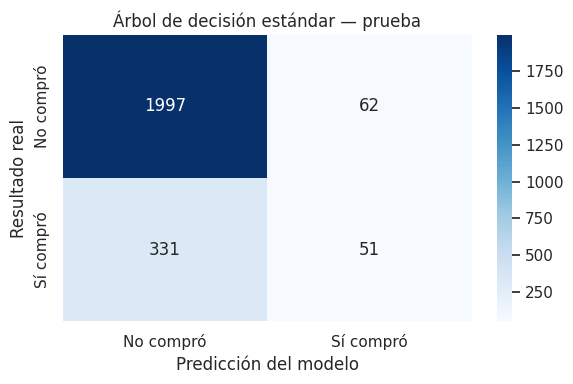

In [13]:
def mostrar_evaluacion(y_real, y_predicho, titulo):
    print('===', titulo, '===')
    print(classification_report(
        y_real, y_predicho, labels=[0, 1],
        target_names=['No compró', 'Sí compró'],
        zero_division=0
    ))

    matriz = confusion_matrix(y_real, y_predicho, labels=[0, 1])
    print('Matriz de confusión:')
    print(matriz)
    tn, fp, fn, tp = matriz.ravel()
    print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')

    plt.figure(figsize=(6, 4))
    sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
                xticklabels=['No compró', 'Sí compró'],
                yticklabels=['No compró', 'Sí compró'])
    plt.xlabel('Predicción del modelo')
    plt.ylabel('Resultado real')
    plt.title(titulo)
    plt.tight_layout()
    plt.show()

mostrar_evaluacion(Y_test, Y_pred_test, 'Árbol de decisión estándar — prueba')

### Evaluar métricas en entrenamiento y prueba

`Accuracy`: aciertos generales. `Precision`: qué proporción de las predicciones de compra fue correcta. `Recall`: qué proporción de las compras reales detectamos. `F1`: equilibrio armónico entre Precision y Recall.

Comparamos entrenamiento con prueba para ver si hay señales de sobreajuste; no basta con medir el desempeño de entrenamiento.

In [14]:
def obtener_metricas(nombre, conjunto, y_real, y_predicho):
    tn, fp, fn, tp = confusion_matrix(y_real, y_predicho, labels=[0, 1]).ravel()
    return {
        'Modelo': nombre,
        'Conjunto': conjunto,
        'Accuracy': accuracy_score(y_real, y_predicho),
        'Precision': precision_score(y_real, y_predicho, zero_division=0),
        'Recall': recall_score(y_real, y_predicho, zero_division=0),
        'F1': f1_score(y_real, y_predicho, zero_division=0),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)
    }

resultados = [
    obtener_metricas('Árbol estándar', 'Entrenamiento', Y_train, Y_pred_train),
    obtener_metricas('Árbol estándar', 'Prueba', Y_test, Y_pred_test)
]
df_resultados = pd.DataFrame(resultados)
display(df_resultados.round(4))

,Modelo,Conjunto,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Árbol estándar,Entrenamiento,0.8439,0.5026,0.1245,0.1996,8050,188,1336,190
1,Árbol estándar,Prueba,0.8390,0.4513,0.1335,0.2061,1997,62,331,51


###  árbol pero con pesos de clases


```python
class_weight={0:0.17, 1:0.83}
```

Usaremos estos valores de referencia como una configuración alternativa para explorar el desbalance. La clase 1 (compra) recibe mayor peso que la clase 0 (no compra). **No se crean registros nuevos**. El objetivo es penalizar más los errores sobre compradores reales.

En este dataset, esos pesos son aproximadamente proporcionales al inverso de las frecuencias de clase. No son probabilidades predichas y no deben interpretarse como un umbral de decisión.

Profundidad: 9
Número de hojas: 24
=== Árbol de decisión con pesos de clase — prueba ===
              precision    recall  f1-score   support

   No compró       0.93      0.67      0.78      2059
   Sí compró       0.29      0.71      0.41       382

    accuracy                           0.68      2441
   macro avg       0.61      0.69      0.59      2441
weighted avg       0.83      0.68      0.72      2441

Matriz de confusión:
[[1381  678]
 [ 111  271]]
TN=1381, FP=678, FN=111, TP=271


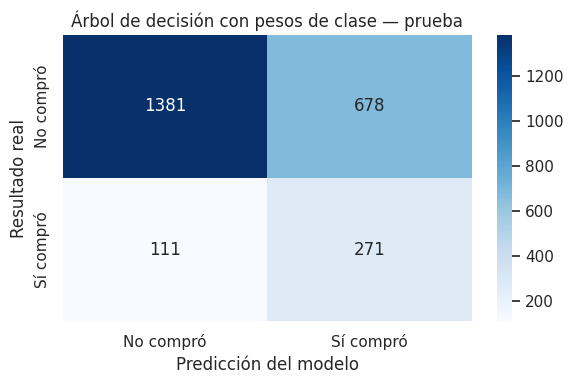

,Modelo,Conjunto,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Árbol estándar,Entrenamiento,0.8439,0.5026,0.1245,0.1996,8050,188,1336,190
1,Árbol estándar,Prueba,0.8390,0.4513,0.1335,0.2061,1997,62,331,51
2,Árbol con pesos,Entrenamiento,0.6951,0.3032,0.7326,0.4289,5669,2569,408,1118
3,Árbol con pesos,Prueba,0.6768,0.2856,0.7094,0.4072,1381,678,111,271


In [15]:
dt_balanceado = DecisionTreeClassifier(
    class_weight={0:0.17, 1:0.83},
    criterion='gini',
    min_samples_leaf=10,
    min_impurity_decrease=0.001,
    random_state=42
)
dt_balanceado.fit(X_train_cod, Y_train)

Y_pred_train_bal = dt_balanceado.predict(X_train_cod)
Y_pred_test_bal = dt_balanceado.predict(X_test_cod)

print('Profundidad:', dt_balanceado.get_depth())
print('Número de hojas:', dt_balanceado.get_n_leaves())
mostrar_evaluacion(Y_test, Y_pred_test_bal, 'Árbol de decisión con pesos de clase — prueba')

resultados.extend([
    obtener_metricas('Árbol con pesos', 'Entrenamiento', Y_train, Y_pred_train_bal),
    obtener_metricas('Árbol con pesos', 'Prueba', Y_test, Y_pred_test_bal)
])
df_resultados = pd.DataFrame(resultados)
display(df_resultados.round(4))

### Comparar los dos árboles en prueba

Buscamos comprender el intercambio entre **Precision y Recall**. Un árbol que detecta más compras también puede generar más falsas alarmas.


Métricas de la clase positiva: Sí compró


,Modelo,Accuracy,Precision,Recall,F1,TP,FP,FN,TN
1,Árbol estándar,83.90,45.13,13.35,20.61,51,62,331,1997
3,Árbol con pesos,67.68,28.56,70.94,40.72,271,678,111,1381


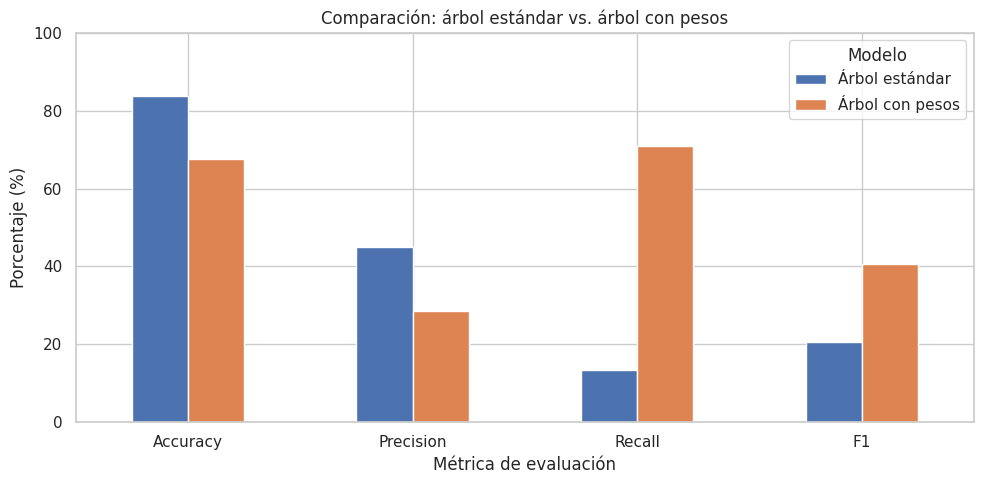

In [16]:
comparacion = df_resultados[df_resultados['Conjunto']=='Prueba'].copy()
for metrica in ['Accuracy', 'Precision', 'Recall', 'F1']:
    comparacion[metrica] = (comparacion[metrica] * 100).round(2)

print('Métricas de la clase positiva: Sí compró')
display(comparacion[['Modelo','Accuracy','Precision','Recall','F1','TP','FP','FN','TN']])

comparacion.set_index('Modelo')[['Accuracy','Precision','Recall','F1']].T.plot(
    kind='bar', figsize=(10, 5)
)
plt.title('Comparación: árbol estándar vs. árbol con pesos')
plt.xlabel('Métrica de evaluación')
plt.ylabel('Porcentaje (%)')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title='Modelo')
plt.tight_layout()
plt.show()

### Graficar el árbol de decisión

utilizamos `tree.plot_tree()`. Aquí visualizaremos **solo las primeras tres decisiones** del árbol con pesos para que la figura sea legible durante la exposición. El algoritmo **sí entrenó el árbol completo**: `max_depth=3` se utiliza en esta llamada **únicamente para el dibujo**, no en `DecisionTreeClassifier`.



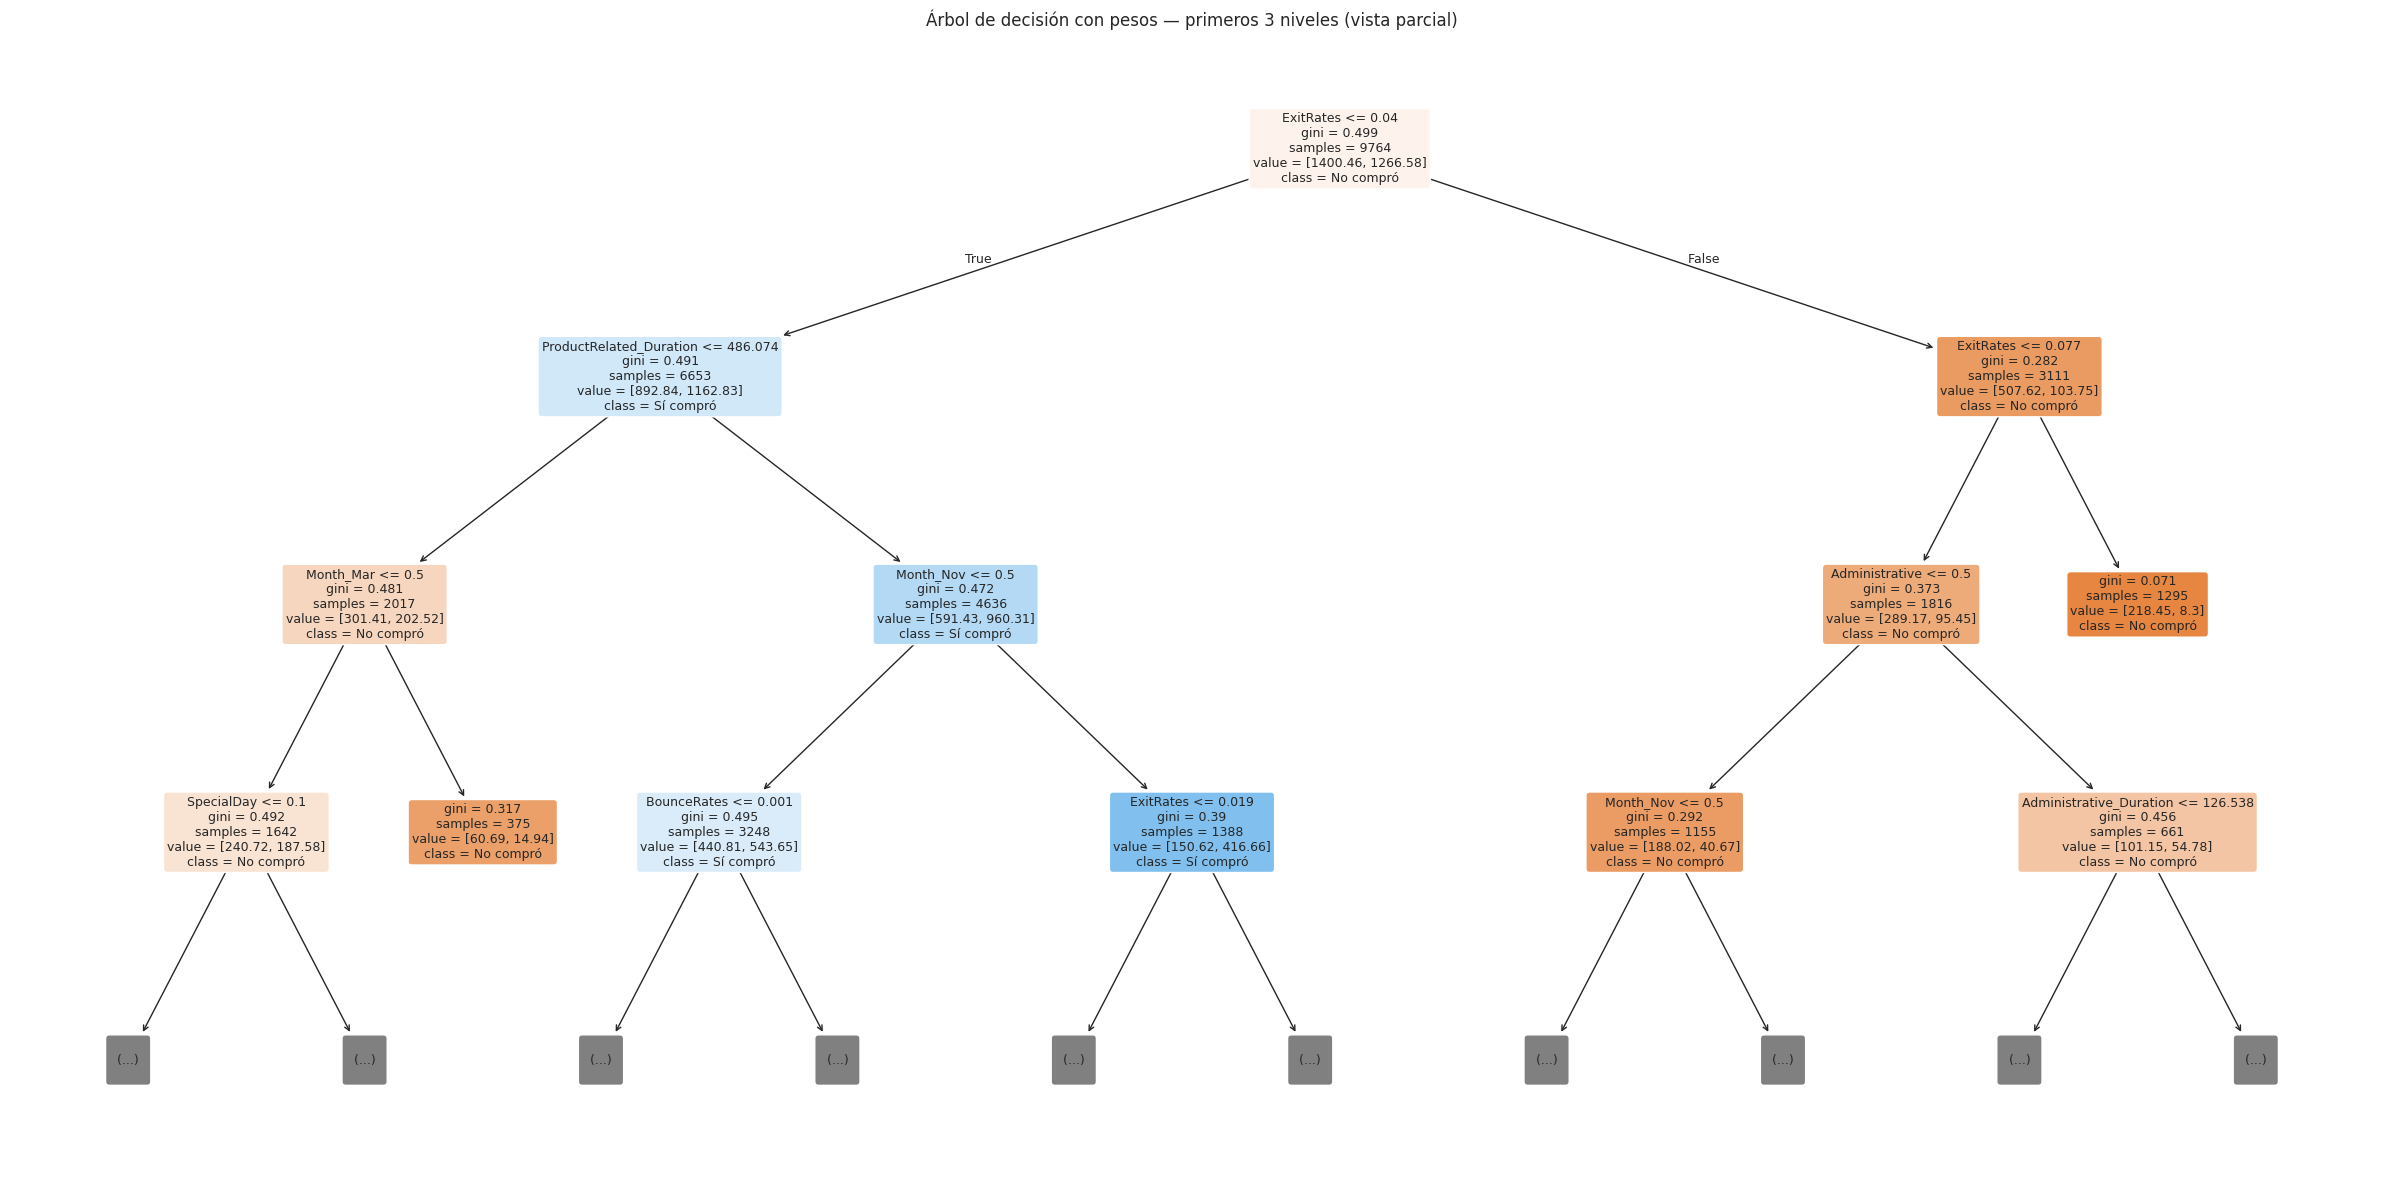

In [17]:
plt.figure(figsize=(24, 12))
tree.plot_tree(
    dt_balanceado,
    feature_names=X_train_cod.columns,
    class_names=['No compró', 'Sí compró'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)
plt.title('Árbol de decisión con pesos — primeros 3 niveles (vista parcial)')
plt.tight_layout()
plt.show()

### ¿Cuáles características utiliza más el árbol?



,Variable,Importancia
7,ExitRates,0.5610
5,ProductRelated_Duration,0.1445
17,Month_Nov,0.0885
6,BounceRates,0.0658
15,Month_Mar,0.0236
4,ProductRelated,0.0218
0,Administrative,0.0178
8,SpecialDay,0.0176
11,Month_Dec,0.0158
16,Month_May,0.0128


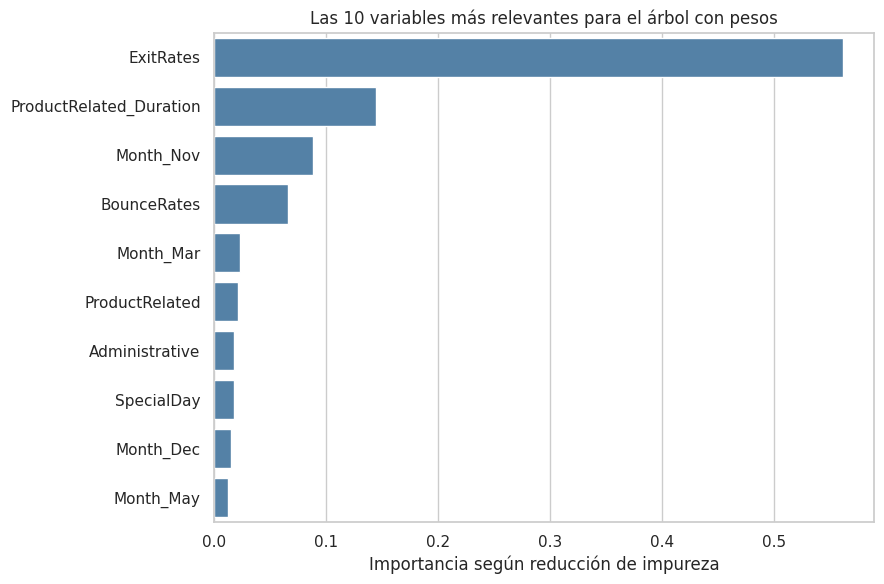

In [18]:
importancias = pd.DataFrame({
    'Variable': X_train_cod.columns,
    'Importancia': dt_balanceado.feature_importances_
})
importancias = importancias.sort_values('Importancia', ascending=False)

display(importancias.head(12).round(4))

plt.figure(figsize=(9, 6))
sns.barplot(data=importancias.head(10), x='Importancia', y='Variable', color='steelblue')
plt.title('Las 10 variables más relevantes para el árbol con pesos')
plt.xlabel('Importancia según reducción de impureza')
plt.ylabel('')
plt.tight_layout()
plt.show()